In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

rng=np.random.default_rng(42)
so_benh_nhan= 500

bmi=rng.uniform(15,40,so_benh_nhan)
print(bmi)
xac_suat_mac_benh=1/(1+np.exp(-(bmi-27)/3.5))

nhan_mac_benh=(
    rng.random(so_benh_nhan)<xac_suat_mac_benh
).astype(int)

du_lieu=pd.DataFrame({
    "BMI": bmi,
    "Mac_benh":nhan_mac_benh
})

print(du_lieu.head())
print("\nSo nguoi mac benh theo nhan: ")
print(du_lieu["Mac_benh"].value_counts())

[34.34890121 25.97196099 36.464948   32.43420073 17.3544337  39.39055879
 34.02849255 34.65160763 18.20284082 26.25964845 24.26995061 38.16912472
 31.096628   35.56904033 26.08535497 20.68096804 28.86461968 16.5954314
 35.6907793  30.79160998 33.9521935  23.8631492  39.26745061 37.32802803
 34.45958743 19.8659677  26.66802509 16.09509414 18.8572373  32.07622383
 33.6190539  39.18774331 23.14563395 24.26149265 26.73889528 19.73678398
 18.24803763 26.89262316 20.67273373 31.74534987 25.92879797 35.8169549
 32.50662755 22.80916603 35.80649503 35.11910894 24.68695948 22.2082026
 32.0623876  18.49381209 19.99770506 15.18405674 34.67310944 31.62127141
 32.62913447 34.51822578 26.47289439 29.2185299  18.49492495 17.86325184
 31.71007404 26.77740515 29.13090266 34.12497144 30.867958   28.83948502
 28.98017902 22.59875245 15.77044586 25.91793473 20.36461682 25.21321609
 36.33507683 20.84848715 16.45756854 22.0345973  22.33984394 31.54791287
 28.92580381 34.59745523 31.60783851 25.15967154 35.35

In [6]:
X=du_lieu[["BMI"]]
y=du_lieu["Mac_benh"]

X_train, X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

mo_hinh=LogisticRegression()
mo_hinh.fit(X_train,y_train)

xac_suat_du_doan=mo_hinh.predict_proba(X_test)[:,1]

nhan_du_doan=mo_hinh.predict(X_test)
do_chinh_xac=accuracy_score(y_test,nhan_du_doan)
ma_tran_nham_lan=confusion_matrix(
    y_test,
    nhan_du_doan,
    labels=[0,1]
)
print(f"Độ chính xác: {do_chinh_xac:.3f}")
print("\nMa trận nhầm lẫn:")
print(ma_tran_nham_lan)

bang_du_doan = pd.DataFrame({
    "BMI": X_test["BMI"].to_numpy(),
    "Xac_suat_mac_benh": xac_suat_du_doan,
    "Nhan_du_doan": nhan_du_doan,
    "Nhan_thuc_te": y_test.to_numpy()
})

print("\nMột số kết quả dự đoán:")
print(bang_du_doan.head(10).round(3))

Độ chính xác: 0.790

Ma trận nhầm lẫn:
[[39  8]
 [13 40]]

Một số kết quả dự đoán:
      BMI  Xac_suat_mac_benh  Nhan_du_doan  Nhan_thuc_te
0  30.650              0.761             1             1
1  16.004              0.032             0             0
2  25.478              0.389             0             1
3  22.098              0.182             0             0
4  20.045              0.105             0             0
5  36.214              0.947             1             1
6  18.695              0.072             0             0
7  17.354              0.048             0             0
8  38.403              0.973             1             1
9  36.875              0.957             1             1


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


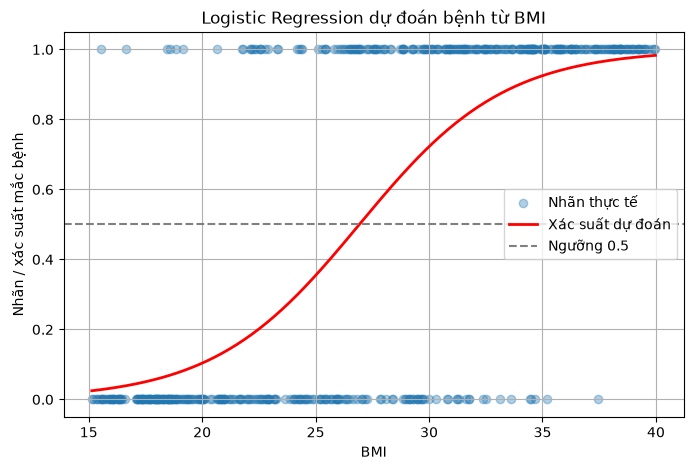

In [7]:
bmi_de_ve=np.linspace(
    du_lieu["BMI"].min(),
    du_lieu["BMI"].max(),
    300
).reshape(-1,1)

xac_suat_de_ve = mo_hinh.predict_proba(bmi_de_ve)[:, 1]

plt.figure(figsize=(8, 5))

# Các điểm dữ liệu thực tế
plt.scatter(
    du_lieu["BMI"],
    du_lieu["Mac_benh"],
    alpha=0.35,
    label="Nhãn thực tế"
)

# Đường xác suất do mô hình học được
plt.plot(
    bmi_de_ve.ravel(),
    xac_suat_de_ve,
    color="red",
    linewidth=2,
    label="Xác suất dự đoán"
)

plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng 0.5")
plt.xlabel("BMI")
plt.ylabel("Nhãn / xác suất mắc bệnh")
plt.title("Logistic Regression dự đoán bệnh từ BMI")
plt.legend()
plt.grid(True)
plt.show()